# Olist: рост и качество покупательского опыта

Цель — выбрать направления улучшения опыта после покупки. Это реконструированное ТЗ для портфолио,
а не заказ Olist. Исходные исследования сохранены в `01_visualization.ipynb`.

Витрины и отчёт: `python scripts/build_portfolio.py`. Ниже исполняемые запросы к результату этой сборки.
Деньги — BRL, GMV без доставки. Доля доставленных — структура финальных статусов, не воронка.


In [1]:
from pathlib import Path
import json
import duckdb
import pandas as pd
from IPython.display import Image, display

candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in candidates if (p / "sql/06_portfolio_marts.sql").exists()), None)
if ROOT is None:
    raise RuntimeError("Запустите notebook из корня проекта или notebooks/")
DB = ROOT / "data/portfolio.duckdb"
if not DB.exists():
    raise FileNotFoundError("Сначала выполните python scripts/build_portfolio.py")

def query(sql):
    with duckdb.connect(str(DB), read_only=True) as con:
        return con.execute(sql).df()

print("Конфигурация анализа:")
print(query("SELECT * FROM analysis_config").to_string(index=False))


Конфигурация анализа:
analysis_start observation_end service_end
    2017-01-01      2018-09-01  2018-07-01


## Качество данных и зерно

Items и payments агрегируются до JOIN, отзыв выбирается один на заказ.
Технический ключ покупателя — customer_unique_id. Проверки ниже должны завершиться без ошибок.


In [2]:
checks = json.loads((ROOT / "reports/data_quality.json").read_text(encoding="utf-8"))
assert all(check["passed"] for check in checks)
display(pd.DataFrame(checks))
print(query("SELECT count(*) orders, count(DISTINCT order_id) unique_orders FROM p_orders").to_string(index=False))


,check,actual,expected,passed
0,orders: unique non-null order_id,0,0,True
1,customers: unique non-null customer_id,0,0,True
2,products: unique non-null product_id,0,0,True
3,sellers: unique non-null seller_id,0,0,True
4,p_orders: unique non-null order_id,0,0,True
5,p_customers: unique non-null customer_unique_id,0,0,True
6,items: unique order/item,0,0,True
7,order -> customer integrity,0,0,True
8,order_items -> order integrity,0,0,True
9,order_payments -> order integrity,0,0,True


 orders  unique_orders
  99421          99421


## 1. За счёт чего растёт GMV?

Сравниваем одинаковые полугодия. GMV = покупатели × заказы на покупателя × AOV.
Финальные два месяца показаны с оговоркой о близости к концу выгрузки.


,period,orders,buyers,gmv,orders_per_buyer,aov
0,2017 H1,13933,13594,1957151.91,1.024937,140.468809
1,2018 H1,40273,39413,5511595.02,1.021820,136.855834


,month,delivered_orders,delivered_buyers,delivered_gmv,aov,gmv_mom_pct
0,2017-01-01,750,718,111798.36,149.064480,NaN
1,2017-02-01,1653,1630,234223.40,141.695947,109.505220
2,2017-03-01,2546,2508,359198.85,141.083602,53.357372
3,2017-04-01,2303,2274,340669.68,147.924307,-5.158471
4,2017-05-01,3546,3479,489338.25,137.997250,43.640094
5,2017-06-01,3135,3076,421923.37,134.584807,-13.776744
6,2017-07-01,3872,3802,481604.52,124.381333,14.145021
7,2017-08-01,4193,4114,554699.70,132.291844,15.177428
8,2017-09-01,4150,4083,607399.67,146.361366,9.500631
9,2017-10-01,4478,4417,648247.65,144.762762,6.725058


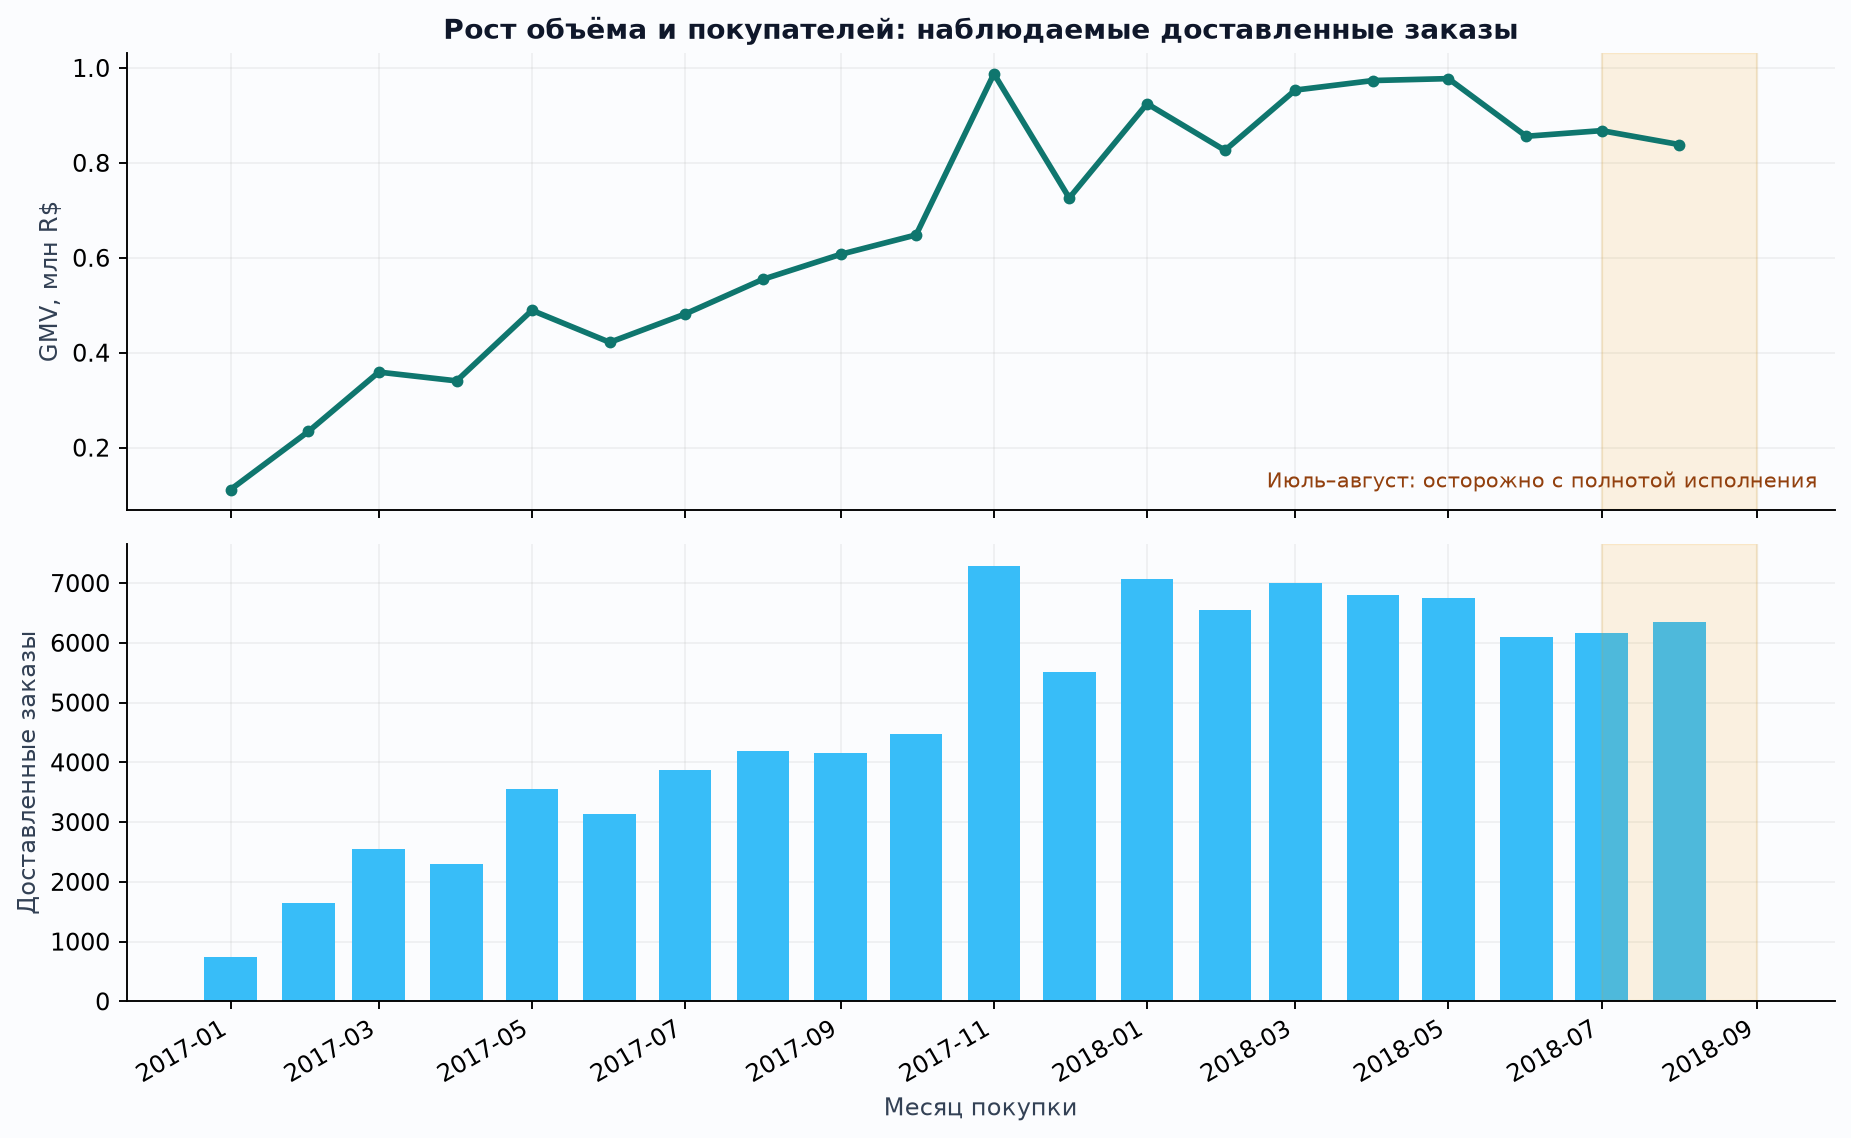

In [3]:
display(pd.read_csv(ROOT / "reports/tables/growth_decomposition.csv"))
display(query("SELECT month, delivered_orders, delivered_buyers, delivered_gmv, aov, gmv_mom_pct FROM a_monthly ORDER BY month"))
display(Image(filename=str(ROOT / "reports/figures/01_growth.png")))


## 2. Возвращаются ли покупатели?

Purchase-repeat90 и календарный retention отвечают разным вопросам. Первые 24 часа проверяем отдельно.
Для 90d в знаменатель входят только зрелые покупатели; для M0–M6 неполные месяцы имеют NULL.
Июньская 90d-когорта может быть зрелой только частично.


,cohort_month,cohort_buyers,eligible_buyers,repeat_buyers,repeat_rate_pct,same_day_repeat_buyers,repeat_after_1d_buyers,repeat_after_1d_rate_pct,delivery_eligible_buyers,delivery_repeated_buyers,repeat_after_delivery_rate_pct
0,2017-01-01,717,717,26,3.626220,21,6,0.836820,717,6,0.836820
1,2017-02-01,1628,1628,28,1.719902,14,15,0.921376,1628,13,0.798526
2,2017-03-01,2503,2503,62,2.477028,32,32,1.278466,2503,32,1.278466
3,2017-04-01,2256,2256,48,2.127660,20,29,1.285461,2256,23,1.019504
4,2017-05-01,3451,3451,98,2.839757,44,55,1.593741,3450,44,1.275362
5,2017-06-01,3037,3037,86,2.831742,43,43,1.415871,3037,36,1.185380
6,2017-07-01,3752,3752,97,2.585288,52,48,1.279318,3752,42,1.119403
7,2017-08-01,4057,4057,112,2.760661,58,58,1.429628,4057,51,1.257087
8,2017-09-01,4004,4004,114,2.847153,46,71,1.773227,4004,65,1.623377
9,2017-10-01,4328,4328,97,2.241220,44,53,1.224584,4328,50,1.155268


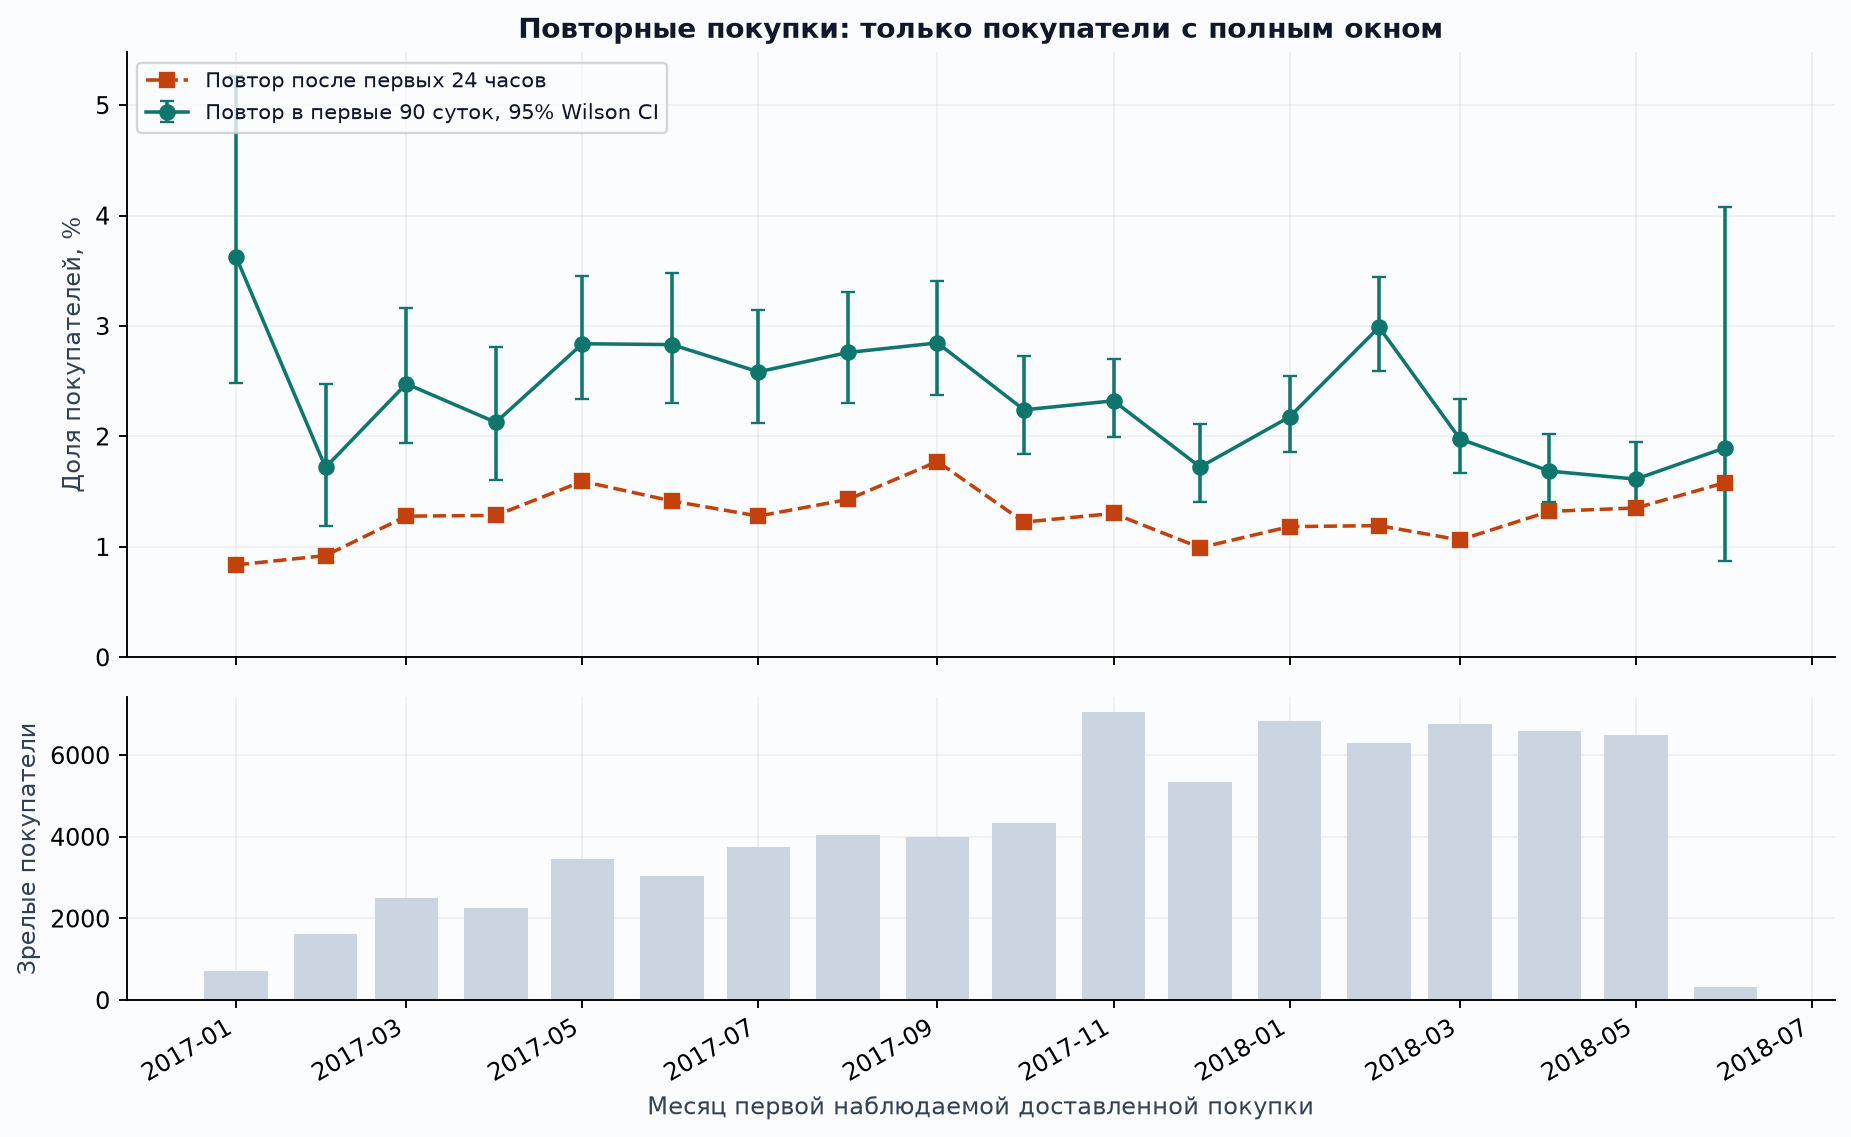

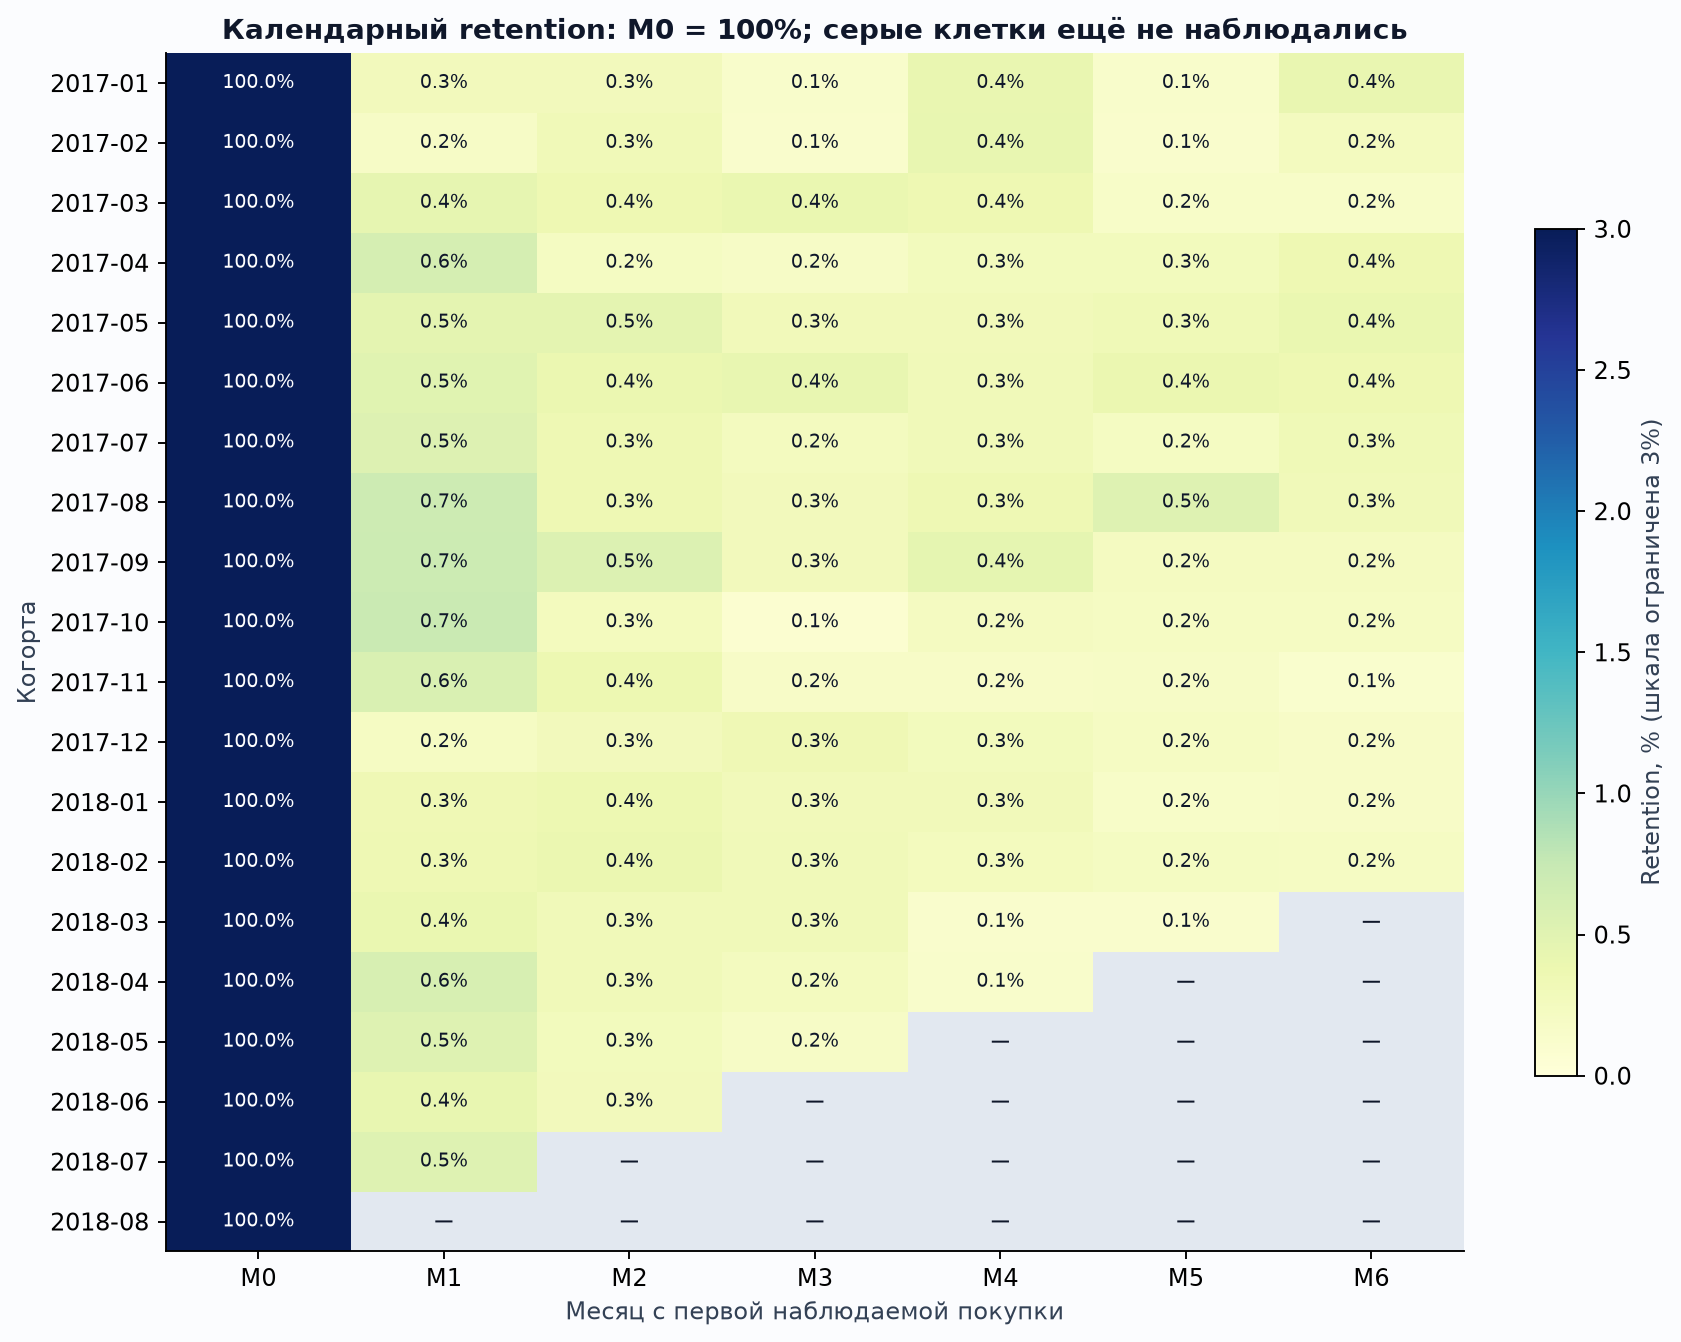

In [4]:
display(query("SELECT * FROM a_repeat90 ORDER BY cohort_month"))
display(Image(filename=str(ROOT / "reports/figures/02_repeat90.png")))
display(Image(filename=str(ROOT / "reports/figures/03_retention.png")))


## 3. Где сосредоточены опоздания?

Покупки 01.01.2017–30.06.2018, только delivered. Консервативный буфер до cutoff не гарантирует полноту.
Приоритет определяем по абсолютному числу поздних заказов и доле с явным знаменателем.


,customer_state,delivered_orders,known_date_orders,late_orders,late_rate_pct,median_delivery_days,p90_delivery_days,reviewed_orders,low_review_orders,low_review_rate_pct
0,RJ,10891,10891,1436,13.185199,12.838194,30.671829,10765,2076,19.284719
1,SP,34527,34523,1432,4.147959,7.585046,16.203081,34329,3714,10.818841
2,MG,9975,9975,499,5.002506,10.979722,20.921106,9912,1195,12.056094
3,BA,2849,2849,380,13.338013,17.909988,32.568738,2824,511,18.094901
4,RS,4727,4726,311,6.580618,13.933744,26.948935,4710,580,12.314225
5,SC,3141,3141,281,8.946195,13.819815,26.627002,3115,425,13.643660
6,ES,1767,1767,205,11.601585,14.179178,26.219324,1743,252,14.457831
7,PR,4262,4262,183,4.293759,11.036939,20.809666,4242,489,11.527581
8,CE,1134,1134,175,15.432099,18.966418,35.939051,1128,207,18.351064
9,PE,1368,1368,141,10.307018,16.742575,32.357780,1354,210,15.509601


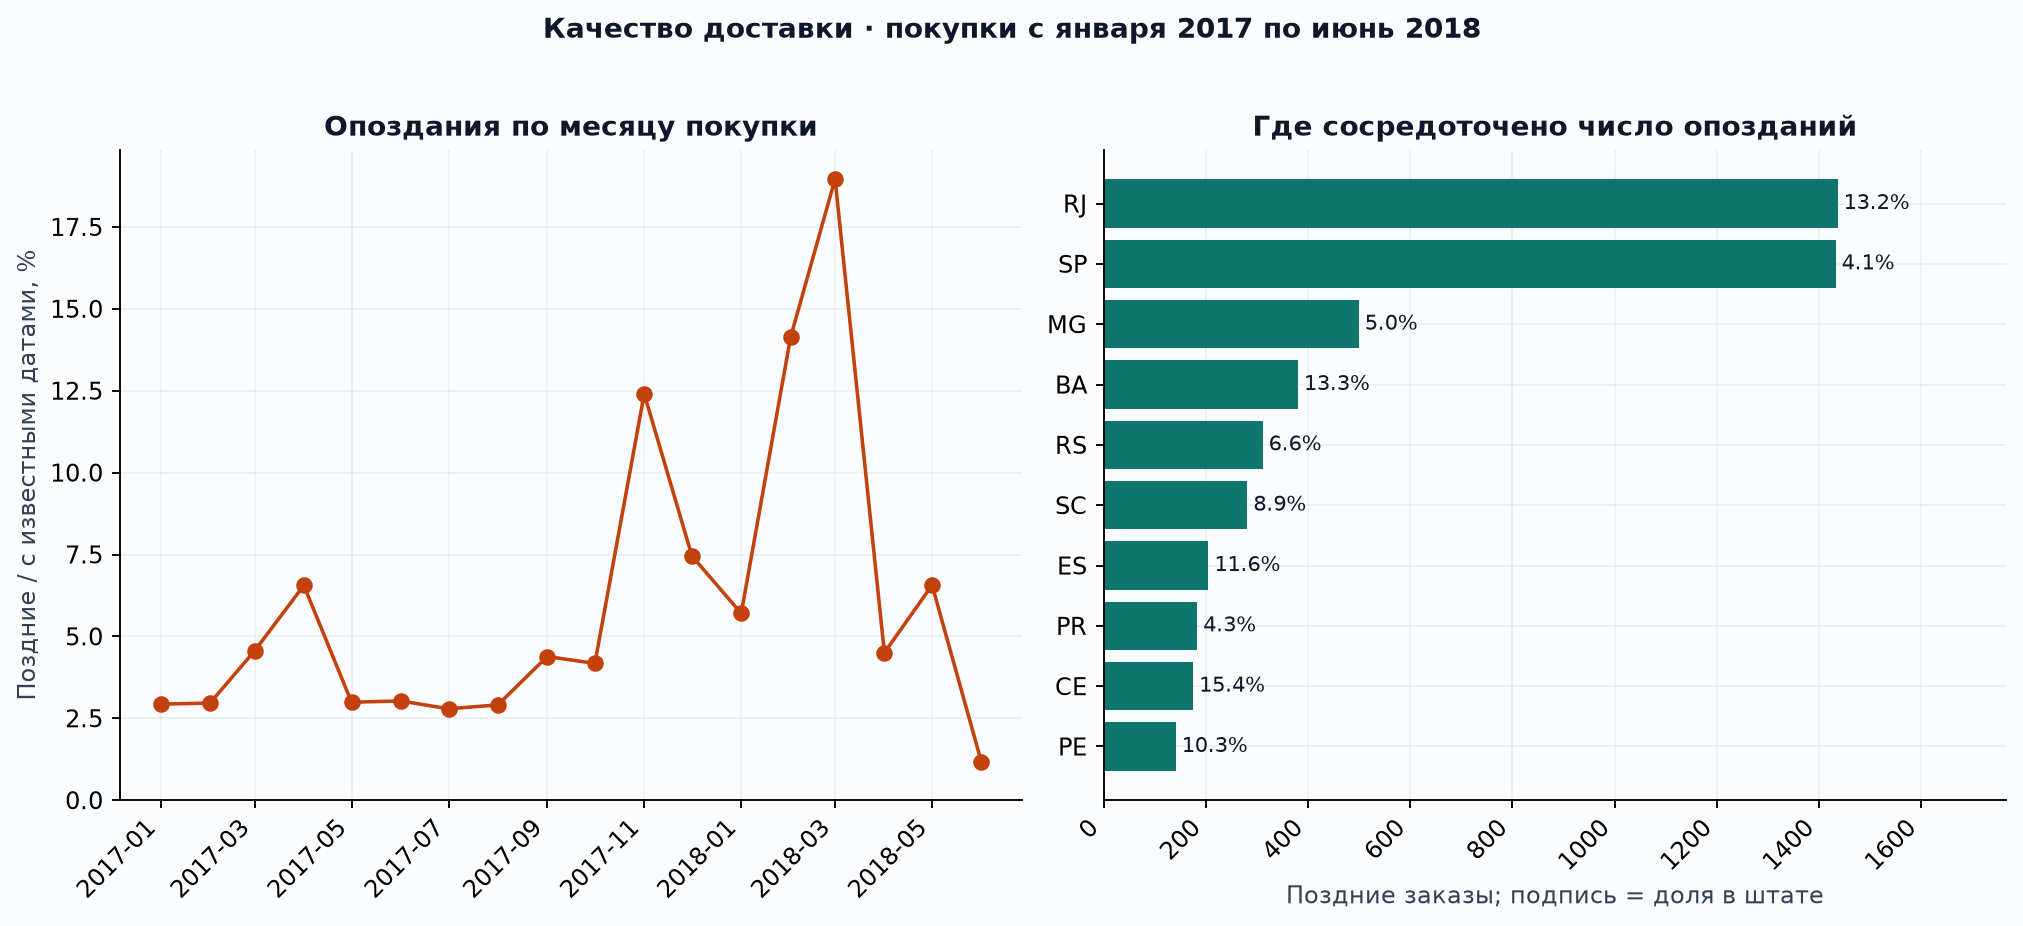

In [5]:
display(query("SELECT * FROM a_service_segments ORDER BY late_orders DESC LIMIT 10"))
display(Image(filename=str(ROOT / "reports/figures/04_delivery.png")))


## 4. Как связаны доставка, отзывы и повтор?

Оценки 1–2 считаем среди заказов с выбранным отзывом и известной своевременностью.
95% CI разницы — кластерный bootstrap по покупателям. Стандартизация month × state описательная.
Повтор после доставки имеет собственную точку отсчёта; нельзя использовать предшествовавшие ему заказы.


,is_late,reviewed_orders,avg_review_score,low_review_orders,low_review_rate_pct,reviewed_after_delivery_orders,low_review_after_delivery_orders,avg_review_after_delivery_score,low_review_after_delivery_rate_pct
0,False,77319,4.276957,7316,9.462099,77147,7287,4.277626,9.445604
1,True,5793,2.206111,3716,64.146384,1627,328,3.679779,20.159803


,is_late,eligible_buyers,repeated_buyers,repeat_pct,ci95_low_pct,ci95_high_pct
0,False,67811,791,1.166477,1.088384,1.250103
1,True,5264,42,0.797872,0.590840,1.076664


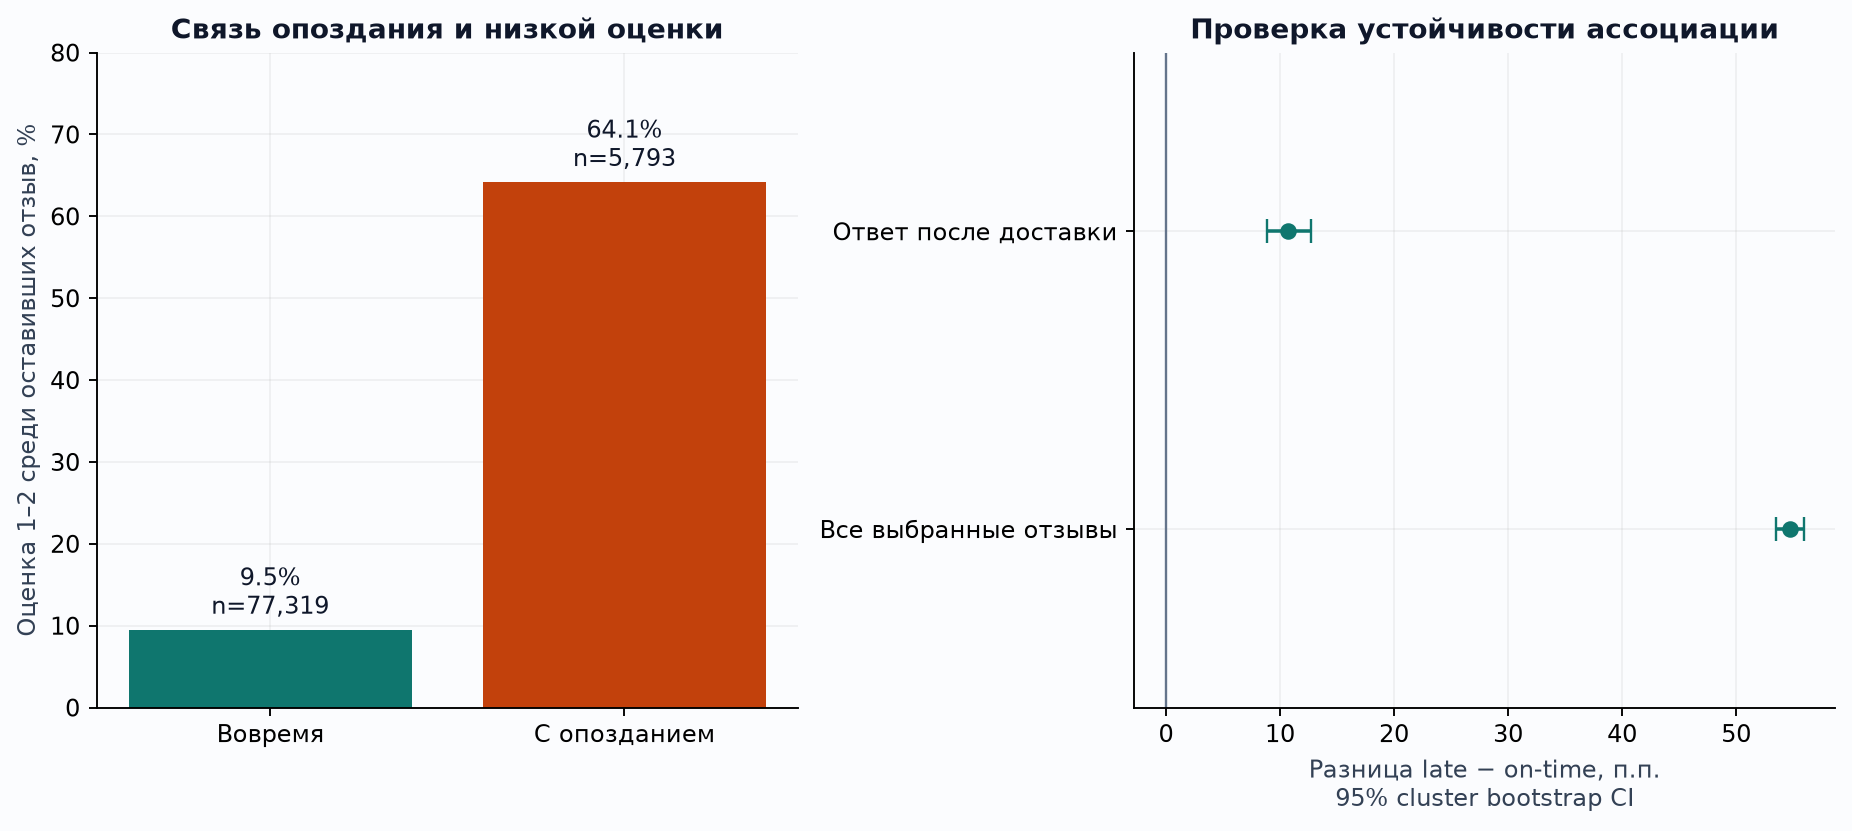

{
  "review_low_score": {
    "difference_pp": 54.68428498775735,
    "ci95_pp": [
      53.45067614003636,
      55.90828693785531
    ],
    "buyers": 80462,
    "orders": 83112,
    "late_n": 5793,
    "on_time_n": 77319,
    "late_rate": 0.6414638356637321,
    "on_time_rate": 0.09462098578615864,
    "iterations": 2000,
    "seed": 42
  },
  "review_after_delivery": {
    "difference_pp": 10.714199471791211,
    "ci95_pp": [
      8.83973714459282,
      12.710424086639616
    ],
    "buyers": 76436,
    "orders": 78774,
    "late_n": 1627,
    "on_time_n": 77147,
    "late_rate": 0.2015980331899201,
    "on_time_rate": 0.09445603847200798,
    "iterations": 2000,
    "seed": 42
  },
  "month_state_standardized_difference_pp": 50.372927059221716
}


In [6]:
statistics = json.loads((ROOT / "reports/statistics.json").read_text(encoding="utf-8"))
display(query("SELECT * FROM a_review_delivery ORDER BY is_late"))
print(json.dumps({k: statistics[k] for k in ["review_low_score", "review_after_delivery", "month_state_standardized_difference_pp"]}, ensure_ascii=False, indent=2))
display(pd.read_csv(ROOT / "reports/tables/repeat_after_delivery_by_lateness.csv"))
display(Image(filename=str(ROOT / "reports/figures/05_reviews.png")))


## 5. Ассортимент и проверяемое решение

Категории — контекст спроса. Без маржи и экспозиции нельзя обосновать инвестиции только GMV.
Рекомендация: диагностика логистики и эксперимент проактивной коммуникации при риске задержки.
Рандомизация по покупателю до уведомления, ITT, фиксированный follow-up150d; отсутствие доставки
не исключает покупателя. Baseline ниже — proxy из conditional delivered, требующий shadow cohort.


,category_name,gmv,gmv_share_pct
0,health_beauty,1229557.50,9.328237
1,watches_gifts,1163465.91,8.826823
2,bed_bath_table,1022955.77,7.760820
3,sports_leisure,952840.40,7.228878
4,computers_accessories,888055.59,6.737378
5,furniture_decor,706237.17,5.357983
6,housewares,614341.62,4.660802
7,cool_stuff,609158.00,4.621476
8,auto,577838.39,4.383865
9,garden_tools,469135.40,3.559172


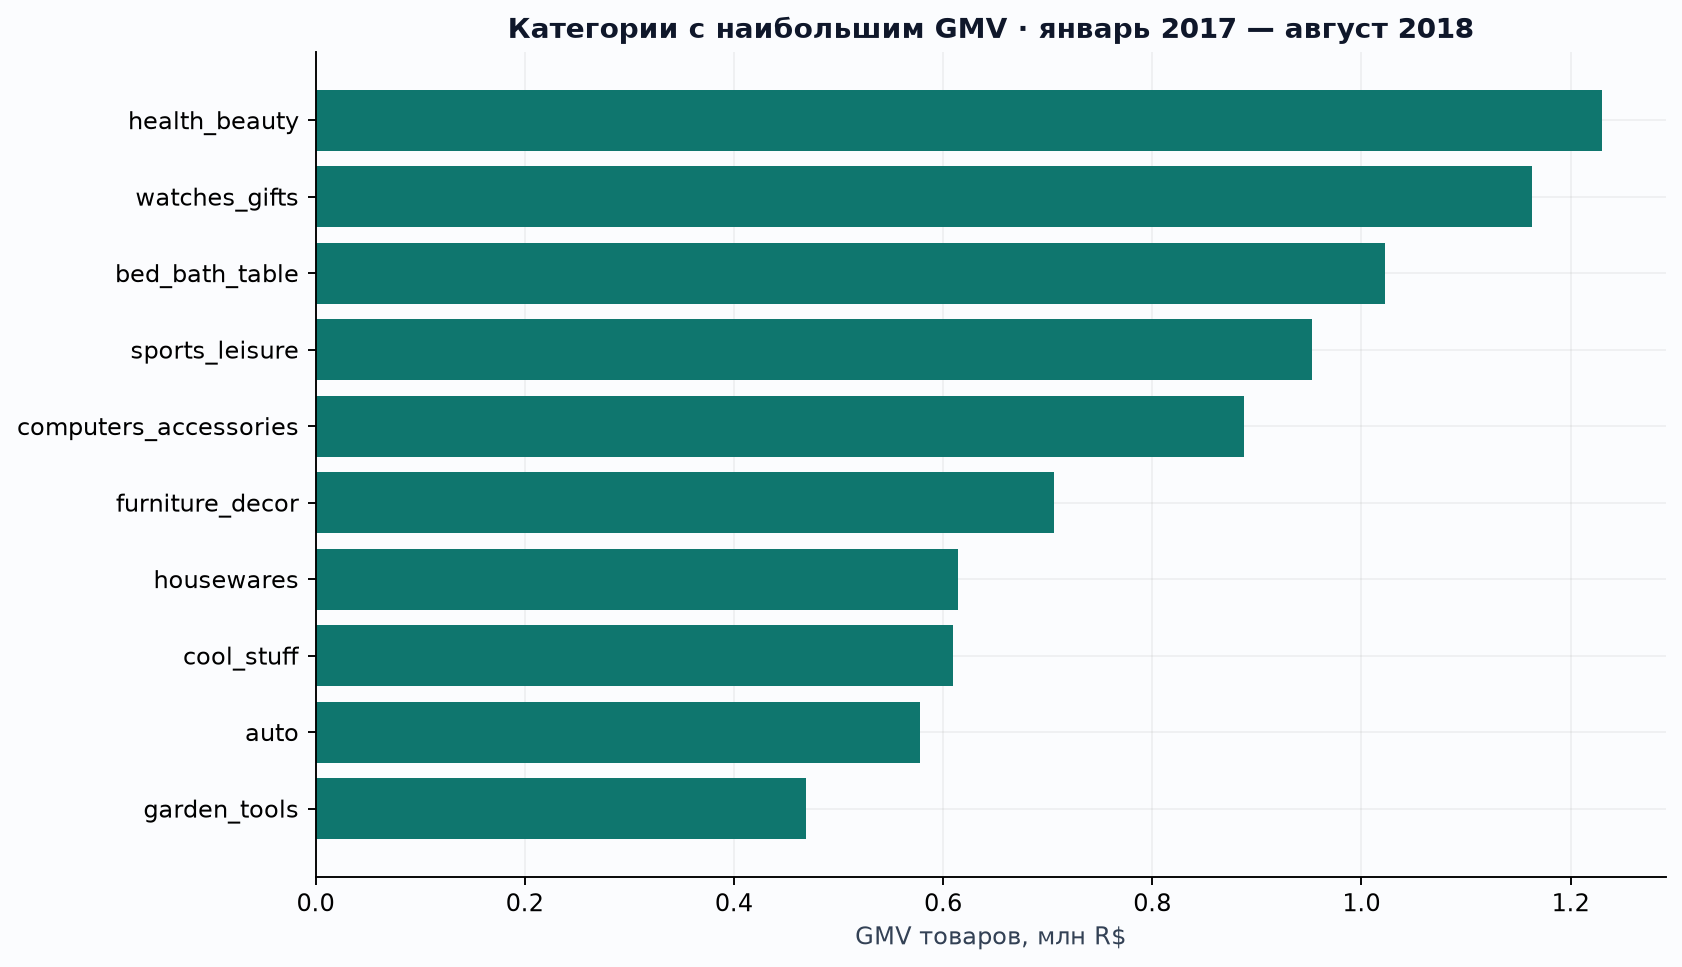

{
  "baseline_proxy": 0.011399247348614437,
  "absolute_mde": 0.005,
  "alpha": 0.05,
  "power": 0.8,
  "buyers_per_arm": 8605,
  "total_buyers": 17210,
  "note": "Planning proxy from delivered buyers; re-estimate in the eligible ITT shadow cohort."
}


In [7]:
display(query("SELECT category_name, gmv, gmv_share_pct FROM a_categories ORDER BY gmv DESC LIMIT 10"))
display(Image(filename=str(ROOT / "reports/figures/06_categories.png")))
print(json.dumps(statistics["experiment"], ensure_ascii=False, indent=2))


## Выводы и границы применимости

Численные выводы и действия — в [готовом отчёте](../reports/executive_summary.md).
Дизайн будущего теста — в [experiment_design.md](../docs/experiment_design.md).

Это наблюдательные исторические данные. Статусы/отзывы — финальный снимок, история слева и справа ограничена.
Связь late с низкой оценкой не доказывает влияние задержки. Нет трафика, комиссий и затрат:
не рассчитываем purchase conversion, CAC, прибыль, LTV бизнеса, NPS и фактический A/B-эффект.
Источник: [Olist / Kaggle](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce), CC BY-NC-SA4.0.
